# The American Affordability Index

This executed notebook inspects validated outputs. The production transformations live in `src/` and `sql/`. The headline covers selected essentials and aggregate renter income, not every household’s financial well-being.

In [1]:
from pathlib import Path
import json
import pandas as pd
import duckdb
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
P = ROOT/'data/processed'
quality = json.loads((ROOT/'reports/validation_results.json').read_text())
quality

{'checks_passed': True,
 'source_resources': 695,
 'acs_rows': 7488,
 'acs_expected_rows': 7488,
 'acs_state_year_rows': 459,
 'acs_national_year_rows': 9,
 'acs_missing_estimates': 0,
 'acs_missing_moes': 0,
 'burden_universe_reconciliations': 468,
 'price_missing_values': 3,
 'source_bytes': 66692256}

## The coverage gate

Nine standard ACS survey years, 50 states, DC and national totals. The 2020 ACS gap stays visible. Prices are national; no price observations are invented for states.

In [2]:
acs = pd.read_parquet(P/'acs_observations.parquet')
acs.groupby('year').agg(geographies=('geography_id','nunique'), rows=('variable','size'))

,geographies,rows
year,,
2015,52,832
2016,52,832
2017,52,832
2018,52,832
2019,52,832
2021,52,832
2022,52,832
2023,52,832
2024,52,832


## National affordability

The fixed 2015 annual budget is $12,000 rent, $4,800 groceries and $1,800 gasoline. Baseline dollars grow by official price relatives. This budget is illustrative.

In [3]:
national = pd.read_parquet(P/'mart_national.parquet')
national[['year','renter_income','modeled_annual_cost','affordability_index']]

,year,renter_income,modeled_annual_cost,affordability_index
0,2015,35863.0,18600.000000,100.000000
1,2016,37264.0,18784.153784,102.887867
2,2017,38944.0,19451.238936,103.838789
3,2018,40531.0,20167.498658,104.232129
4,2019,42479.0,20613.186168,106.879764
5,2020,NaN,20895.632067,NaN
6,2021,44913.0,22007.391971,105.844870
7,2022,49201.0,24186.874046,105.501957
8,2023,51719.0,25383.071386,105.675005
9,2024,54446.0,26153.810876,107.968565


In [4]:
db = duckdb.connect(str(ROOT/'data/warehouse/affordability.duckdb'), read_only=True)
display(db.sql('SELECT category,baseline_annual_usd,modeled_annual_usd,contribution_usd FROM mart_components WHERE year=2024 ORDER BY contribution_usd DESC').df())
db.close()

,category,baseline_annual_usd,modeled_annual_usd,contribution_usd
0,rent,12000,17622.910963,5622.910963
1,food,4800,6073.781631,1273.781631
2,gasoline,1800,2457.118283,657.118283


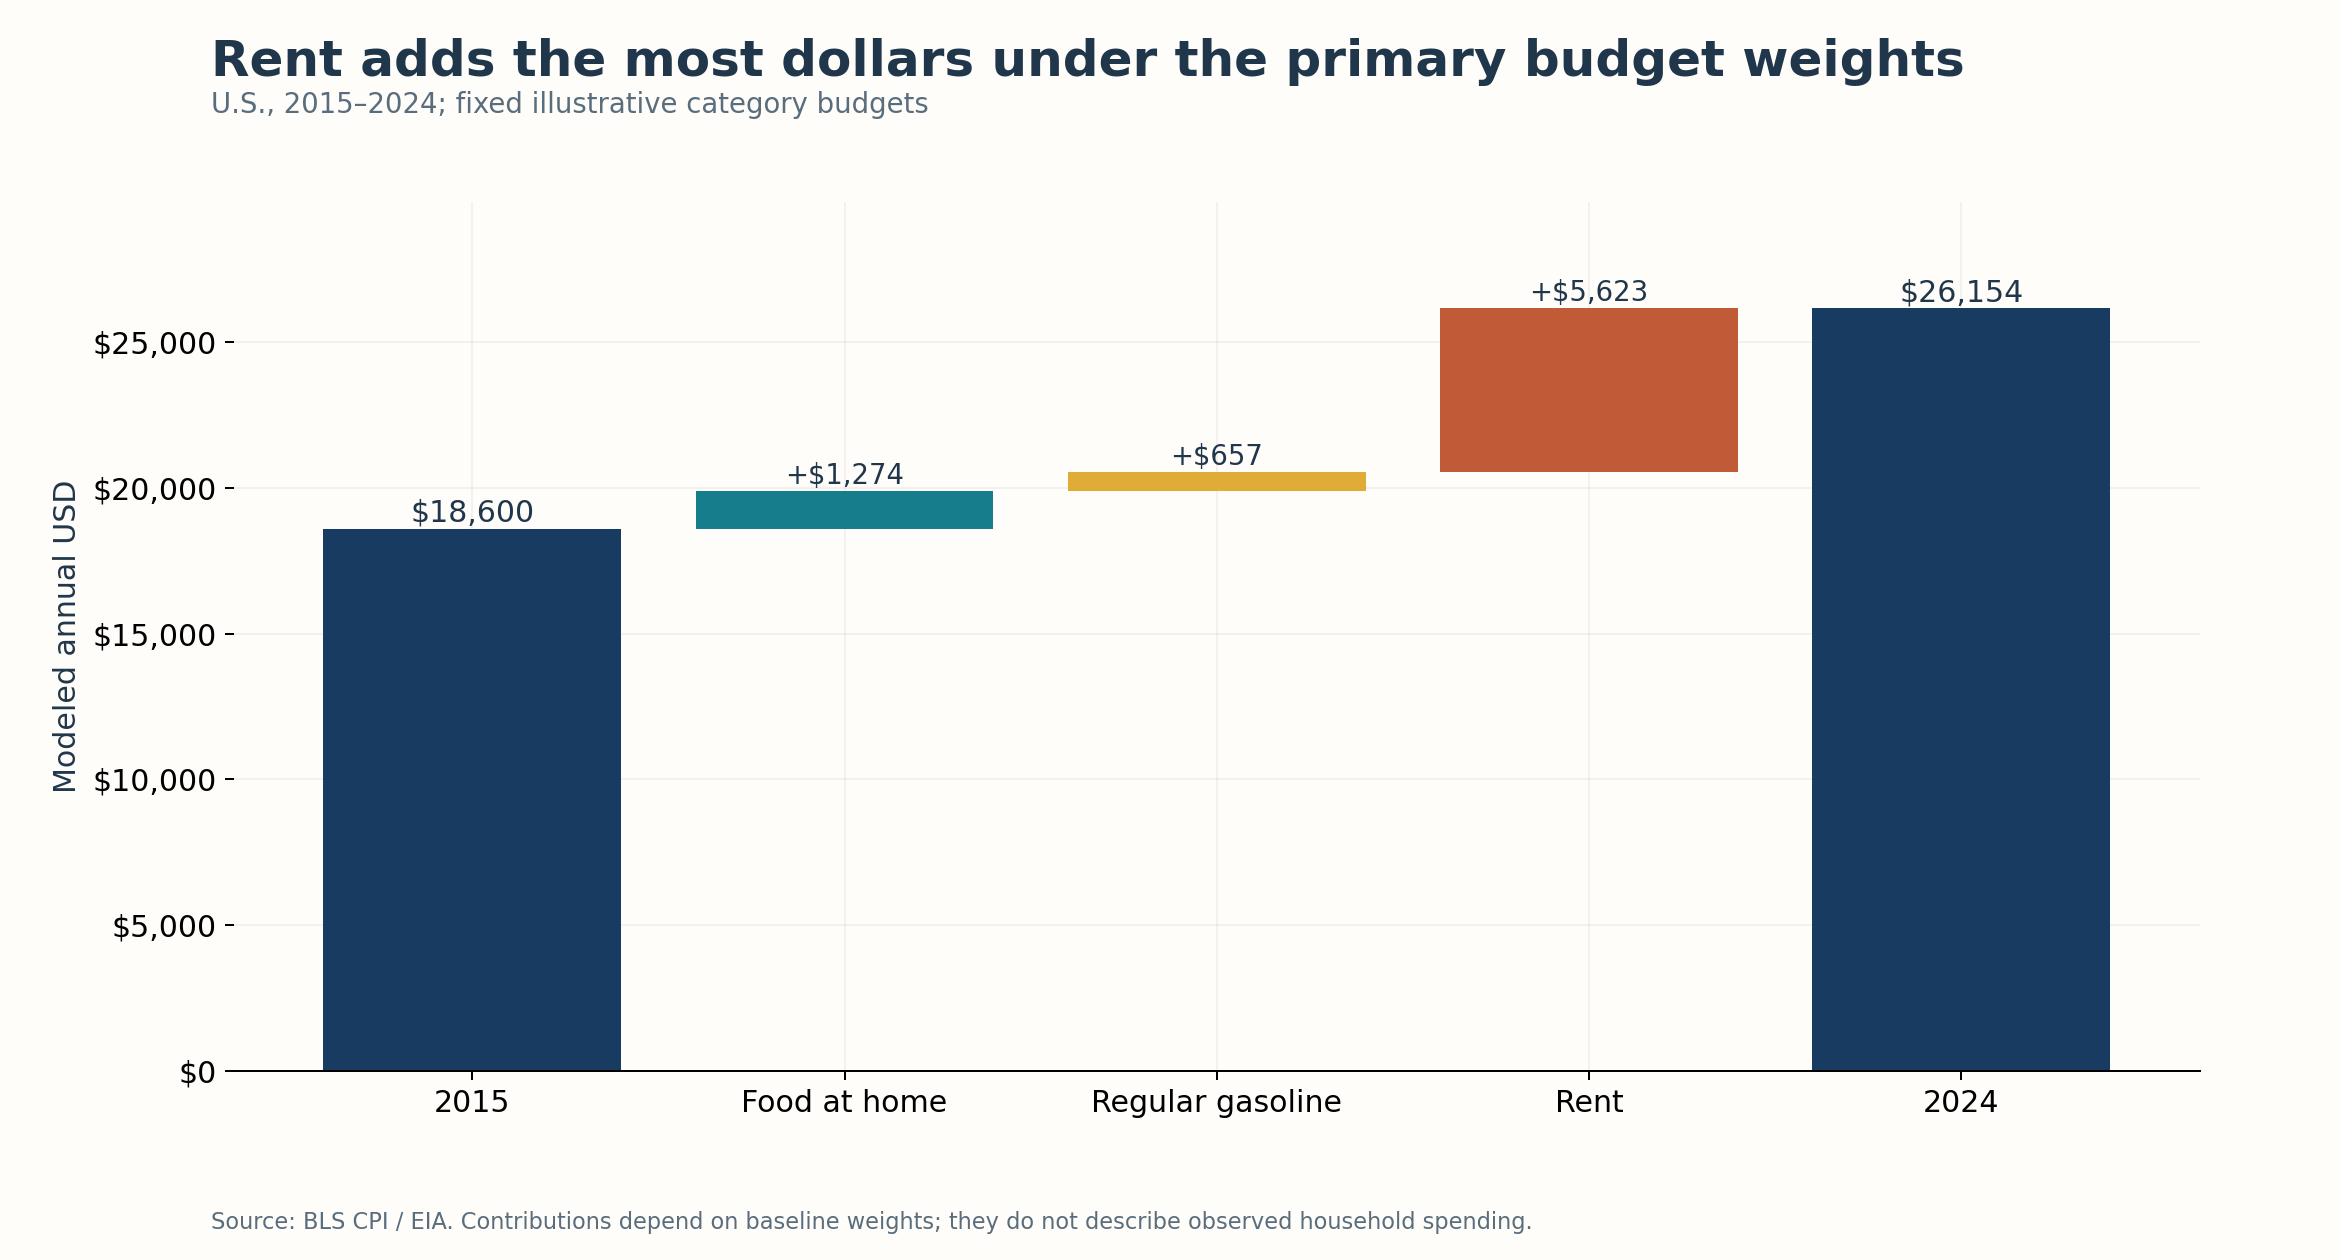

In [5]:
display(Image(filename=str(ROOT/'visuals/04_cost_contributions.png'), width=950))

## Geographic housing comparison

Gross rent/income ratios are ratios of medians. Actual burden prevalence uses ACS B25070 counts and excludes not-computed cases. Published input MOEs are retained; close point-estimate ranks may not be distinct.

In [6]:
states = pd.read_parquet(P/'mart_state_housing.parquet')
states.query('year==2024').sort_values('renter_rent_proxy')[['name','renter_rent_proxy','burden_share','gross_rent_moe','renter_income_moe']].head(10)

,name,renter_rent_proxy,burden_share,gross_rent_moe,renter_income_moe
433,North Dakota,0.236306,0.361348,30.0,2254.0
440,South Dakota,0.258473,0.418998,31.0,2761.0
449,Wyoming,0.259947,0.428792,38.0,3555.0
425,Montana,0.265619,0.426695,42.0,3100.0
414,Iowa,0.268240,0.432464,15.0,1841.0
415,Kansas,0.270788,0.433929,18.0,1805.0
426,Nebraska,0.270795,0.465144,17.0,1507.0
401,Alaska,0.271212,0.414656,48.0,3483.0
448,Wisconsin,0.277151,0.449239,10.0,1108.0
424,Missouri,0.284388,0.452444,14.0,1325.0


## Relationship checks

Price levels and consecutive monthly changes answer different questions. Multiple lags and shared inflation trends do not establish causality.

In [7]:
pd.DataFrame(json.loads((ROOT/'reports/correlation_sensitivity.json').read_text())).T

,n,pearson,spearman
levels,140.0,0.751241,0.706371
monthly_changes,138.0,-0.072563,0.006290
linear_detrended_levels,140.0,0.334043,0.342735
month_demeaned_changes,138.0,-0.153231,-0.074022
common_cpi_deflated_levels,140.0,-0.097624,-0.123662
exclude_2020_2023_changes,90.0,-0.138996,-0.120287
pre_pandemic,59.0,-0.205709,-0.144594
pandemic,24.0,-0.470482,-0.178261
shock_adjustment,24.0,0.381170,0.331304
recent,31.0,-0.133776,-0.149194


In [8]:
pd.read_parquet(P/'price_scenarios.parquet')

,scenario,historical_quantile,reference_date,current_annualized_cost,terminal_annualized_cost,terminal_monthly_cost,modeled_next_12mo_outlay,rent_growth_pct,food_growth_pct,gasoline_growth_pct
0,Low,0.25,2026-09-01,28507.62664,28861.035906,2405.086325,28693.549174,3.617211,0.449308,-11.084667
1,Baseline,0.50,2026-09-01,28507.62664,29147.986763,2428.998897,28851.654989,3.771782,1.190791,-4.581344
2,High,0.75,2026-09-01,28507.62664,30105.754642,2508.812887,29364.623289,5.108815,3.498439,12.660323


## Interpretation

The observed result is modeled improvement relative to 2015, despite higher selected prices. Rent drives most of the modeled dollar increase. Report both facts. Scenario paths are assumptions, not forecasts. Full limitations and recommendations are in `reports/executive_summary.md`.